# TCN-VAE latent spaces on the Nature data

A temporal-convolutional VAE with the conv VAE's latent, so every score and view of notebooks 02 and 05 applies unchanged
(`ml/common/models/seq_vae.py`, `TCNVAE`; trainer `ml/nature/awareness/train_vae.py --arch tcn`). Temporal convolutional
networks match or beat recurrent ones on sequence modelling and forecasting (Bai, Kolter and Koltun 2018); this asks
whether that holds for the awareness latent.

| part | layout |
|---|---|
| encoder | residual blocks of two dilated causal convolutions (kernel 3, width 64, BatchNorm, ReLU, 1x1 skip where widths change); the dilation doubles per block until every output sees the whole window: 6 blocks (1 to 32, receptive field 253 samples, 1.3 s) at 1 s, 8 blocks (1 to 128, 1,021 samples, 5.1 s) at 3 s; outputs averaged over 8 equal segments, 1x1 heads to the mean and log variance: 4 filters x 8 steps, as the conv VAE |
| decoder | non-autoregressive: the latent mapped to width 64 and interpolated back to every sample, the same blocks with the dilations reversed, a linear 1x1 map to the channels (linear, so standardized signals can take either sign) |
| size | 293 to 395 k parameters, by window and channels (conv VAE 30 to 34 k, LSTM-VAE 107 to 109 k, Transformer VAE 217 to 251 k) |
| training | as the other VAEs (AE settings, bf16 autocast, early stopping on the validation negative ELBO) |

**Why it might help**: a TCN sees a fixed, known span of the past at every sample, with no recurrent memory to fade, and
its dilations reach whole gait cycles in a few layers; the encoder is causal within the window, as the LSTM-VAE's.

**Runs**: the four inputs x β 1, 32, 128 with fixed decoder variance and β 1 with the learned one x three seeds: 48 runs
on ID-safe tasks, pulled to `runs/vae/tcn_vae_*`, plus the same 48 on each class of the training-class ablation
(notebook 07). All 144 are one array: `python ml/nature/awareness/train_class_tasks.py --arch tcn > ml/nature/awareness/slurm/tcn_tasks.txt`,
then `submit.sh --train-class --tasks tcn_tasks.txt`. Every view uses the four validation participants; scores are notebook 05's.


In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature', 'notebooks/nature/model_exploration/onboard'):   # shared code, Nature data, helpers
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import _latent_views as lv
import _vae_runs as vr
import _novelty_scores as ns

ARCH, MODEL_PREFIX, TAG, NB = 'tcn', 'TCN-VAE ·', 'tcn_vae', '08'   # architecture shown here and figure prefix (02 conv, 03 LSTM, 04 Transformer)
RUNS = Path(os.environ.get('HIPEXO_VAE_RUNS', REPO / 'notebooks' / 'nature' / 'model_exploration' / 'runs' / 'vae'))
DATA = REPO / 'data' / 'processed_nature' / 'ae'                              # built by ml/nature/awareness/ae_data.py
VIEW_CACHE = REPO / 'data' / 'cache' / 'nature' / 'vae_views'
SHOWN_SEED = 0
FIG_DIR = Path.cwd() / 'figures'                                            # figures for Live_Update
FIG_DIR.mkdir(exist_ok = True)
pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

meta = json.loads((DATA / 'meta.json').read_text())
tables = {inputs: pd.read_parquet(DATA / spec['table']) for inputs, spec in meta['inputs'].items()}
found = vr.discover_vae_runs(RUNS, ARCH)
HAVE_RUNS = not found.empty
if HAVE_RUNS:
    runs = {r.run: vr.load_vae_run(r.run, tables[r.inputs]) for r in found.itertuples()}
    print(f'{len(found)} runs in {found.groupby(vr.CELL_COLS).ngroups} cells under {RUNS}; '
          f'code {sorted({r["summary"]["git_sha"] for r in runs.values()})}')
    display(found.pivot_table(index = ['inputs', 'decoder_variance'], columns = 'beta', values = 'seed', aggfunc = 'count').fillna(0).astype(int))
else:
    print(f'No finished {ARCH} VAE runs under {RUNS} yet. Run the grid on the cluster and pull it (commands above), then rerun.')

48 runs in 16 cells under /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/nature/model_exploration/runs/vae; code ['248e43c-dirty']


beta                              1.0    32.0   128.0
inputs          decoder_variance                     
raw_1s          fixed                 3      3      3
                learned               3      0      0
raw_1s_spectral fixed                 3      3      3
                learned               3      0      0
raw_3s          fixed                 3      3      3
                learned               3      0      0
raw_3s_spectral fixed                 3      3      3
                learned               3      0      0

## 1. What was trained

Validation participants, familiar windows for training and early stopping; NLL and KL are per window (summed over its
channels and samples, 16 × 200 on 1 s raw input, 23 channels with the spectral features and 600 samples at 3 s, and
over the 32 latent dimensions). A dimension is *active* when its median posterior
variance on the familiar validation windows is below 0.9 (the Science Robotics study's definition).

In [2]:
if HAVE_RUNS:
    cells, per_seed = vr.get_cell_table(runs, found)
    display(cells)
    display(per_seed.round(4))

seeds best epoch val NLL / window val KL / window          val MSE active dims (of 32)    minutes
inputs          decoder_variance beta                                                                                                    
raw_1s          fixed            1.0        3     18 ± 4     3341.2 ± 2.0    62.34 ± 0.45  0.2504 ± 0.0013          32.0 ± 0.0  3.4 ± 0.3
                                 32.0       3     10 ± 6     3587.7 ± 4.7     6.62 ± 0.06  0.4045 ± 0.0029           8.7 ± 1.5  2.6 ± 0.4
                                 128.0      3      7 ± 2    3822.6 ± 18.3     2.15 ± 0.04  0.5513 ± 0.0114           2.0 ± 0.0  2.4 ± 0.2
                learned          1.0        3     12 ± 2    1939.3 ± 53.0   100.83 ± 2.31  0.2587 ± 0.0034          32.0 ± 0.0  2.2 ± 0.5
raw_1s_spectral fixed            1.0        3    27 ± 15    4718.2 ± 11.6    64.09 ± 1.11  0.2135 ± 0.0050          32.0 ± 0.0  2.9 ± 1.1
                                 32.0       3     15 ± 3    4962.7 ± 12.2     7.36 ± 0.05  0.3198 ± 0.0053           8.0 ± 0.0  2.0 ± 0.1
                                 128.0      3      9 ± 4    5125.9 ± 25.9     3.36 ± 0.09  0.3908 ± 0.0112           3.0 ± 0.0  1.7 ± 0.2
                learned          1.0        3    30 ± 12   1587.4 ± 119.7   115.62 ± 3.63  0.2241 ± 0.0038          32.0 ± 0.0  3.2 ± 1.0
raw_3s          fixed            1.0        3      8 ± 2   10332.1 ± 19.7    91.26 ± 0.19  0.3147 ± 0.0041          32.0 ± 0.0  4.4 ± 0.5
                                 32.0       3      6 ± 2   10711.0 ± 12.6    15.12 ± 0.42  0.3936 ± 0.0026          12.7 ± 0.6  3.5 ± 0.4
                                 128.0      3      4 ± 2   11159.2 ± 23.2     6.02 ± 0.08  0.4870 ± 0.0048           7.7 ± 1.2  3.1 ± 0.4
                learned          1.0        3      7 ± 1    7115.2 ± 64.1   120.85 ± 1.18  0.3205 ± 0.0019          32.0 ± 0.0  3.6 ± 0.1
raw_3s_spectral fixed            1.0        3     13 ± 3   14426.4 ± 41.0    91.86 ± 1.29  0.2529 ± 0.0059          32.0 ± 0.0  6.4 ± 0.9
                                 32.0       3     10 ± 2   14810.9 ± 50.9    15.75 ± 0.49  0.3086 ± 0.0074          15.0 ± 1.0  5.5 ± 0.4
                                 128.0      3     16 ± 7   15192.2 ± 26.0     6.79 ± 0.19  0.3639 ± 0.0038           5.0 ± 0.0  5.9 ± 1.5
                learned          1.0        3    32 ± 14   5067.4 ± 528.0   135.44 ± 1.02  0.2545 ± 0.0032          32.0 ± 0.0  9.2 ± 3.1

best epoch  val NLL / window  val KL / window  val MSE  active dims (of 32)  minutes
inputs          decoder_variance beta  seed                                                                                      
raw_1s          fixed            1.0   0             22         3338.8555          62.7600   0.2489                   32     3.73
                                       1             15         3342.3418          61.8646   0.2511                   32     3.07
                                       2             18         3342.4211          62.4067   0.2511                   32     3.29
                                 32.0  0              4         3586.9731           6.6742   0.4040                    9     2.30
                                       1             12         3592.7959           6.6229   0.4076                    7     2.98
                                       2             15         3583.4700           6.5633   0.4018                   10     2.46
                                 128.0 0              9         3804.8245           2.1736   0.5401                    2     2.28
                                       1              6         3821.7346           2.1669   0.5507                    2     2.59
                                       2              5         3841.3425           2.0953   0.5630                    2     2.48
                learned          1.0   0             14         2000.2040         103.4948   0.2608                   32     2.73
                                       1             11         1913.2076          99.6503   0.2547                   32     2.14
                                       2             11         1904.3496          99.3524   0.2604                   32     1.65
raw_1s_spectral fixed            1.0   0             42         4706.0078          63.0060   0.2082                   32     4.05
                                       1             26         4719.4692          65.2274   0.2141                   32     2.76
                                       2             13         4729.1025          64.0439   0.2183                   32     1.95
                                 32.0  0             16         4949.1841           7.4137   0.3139                    8     2.10
                                       1             17         4966.2769           7.3529   0.3214                    8     2.13
                                       2             12         4972.7471           7.3179   0.3242                    8     1.89
                                 128.0 0             14         5097.1738           3.4640   0.3783                    3     1.94
                                       1              8         5147.3770           3.2947   0.4001                    3     1.56
                                       2              6         5133.0098           3.3095   0.3939                    3     1.53
                learned          1.0   0             16         1725.6333         111.4255   0.2200                   32     2.17
                                       1             38         1518.7679         117.8037   0.2249                   32     3.55
                                       2             37         1517.7802         117.6344   0.2274                   32     4.01
raw_3s          fixed            1.0   0              7        10336.1641          91.1199   0.3155                   32     4.43
                                       1             10        10310.6807          91.1884   0.3102                   32     4.93
                                       2              8        10349.5566          91.4856   0.3183                   32     3.87
                                 32.0  0              5        10696.5361          15.4595   0.3906                   13     3.57
                                       1              4        10717.9980          14.6486   0.3950                   13     3.03
               

## 2. Training curves

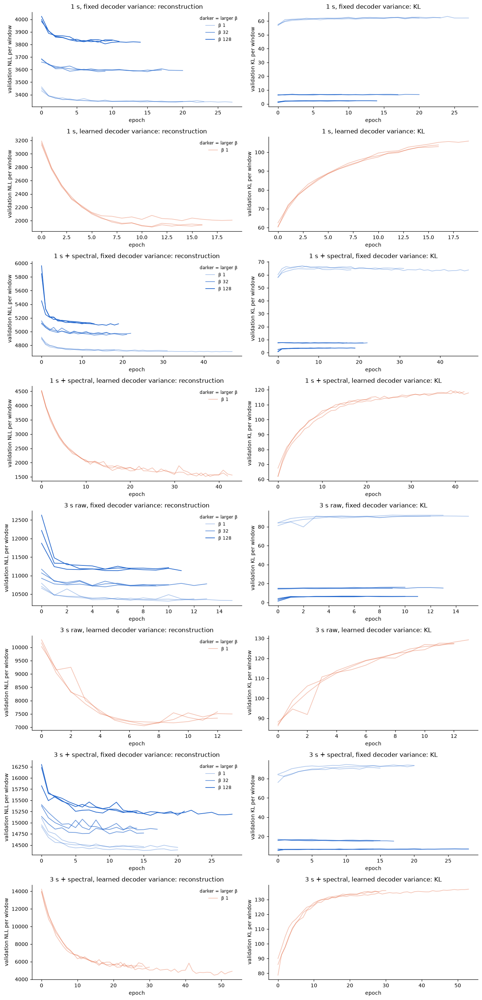

In [3]:
if HAVE_RUNS:
    vr.plot_curves(runs, found)

## 3. How much of the code each VAE uses

Active dimensions and KL against β, per input and decoder variance (compare notebook 02 for the conv VAE).

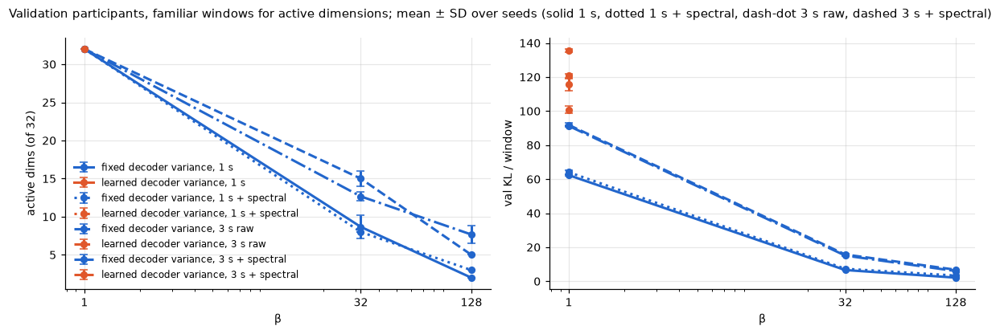

In [4]:
if HAVE_RUNS:
    vr.plot_active_and_kl(per_seed, FIG_DIR / f'{NB}_{TAG}_active_kl.png')

### 3.1 KL per latent dimension

Mean KL of each dimension over the validation participants' windows (seed 0): which of the 32 dimensions carry
information, and whether the same ones survive as β grows. Columns are the 4 filters × 8 time steps.

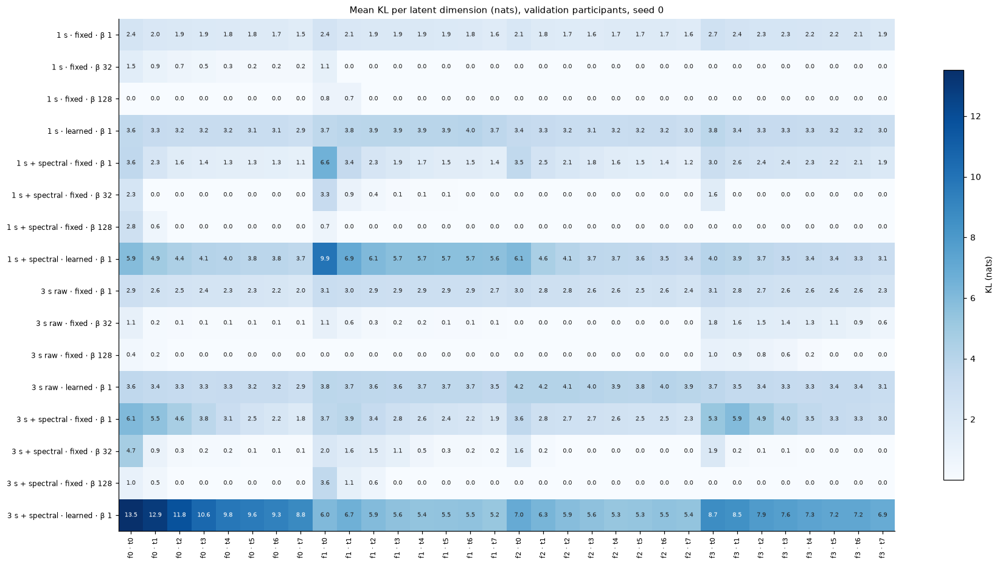

In [5]:
if HAVE_RUNS:
    shown = found[found['seed'] == SHOWN_SEED]
    grid = pd.DataFrame({vr.get_cell_label(r.inputs, r.decoder_variance, r.beta): vr.get_kl_per_dim(runs[r.run]['z'], runs[r.run]['logvar'])
                         for r in shown.itertuples()}).T
    grid.columns = [f'f{u // 8} · t{u % 8}' for u in grid.columns]
    vr.plot_heatmap(grid, f'Mean KL per latent dimension (nats), validation participants, seed {SHOWN_SEED}', 'KL (nats)', '{:.1f}')

## 4. The learned decoder variance

Decoder standard deviation per input channel, in standardized units (1 = the channel's training SD), for the
learned-variance runs: which channels the decoder reconstructs confidently. The fixed-variance runs have 1 everywhere.

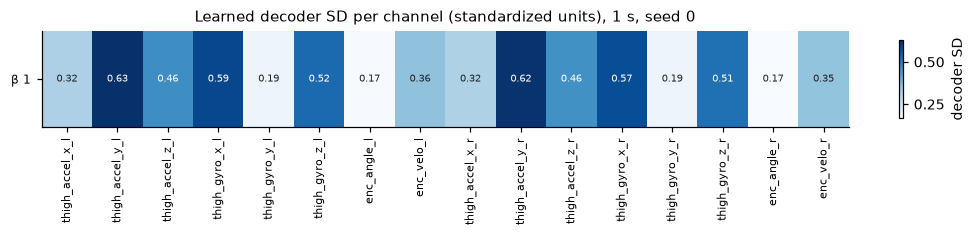

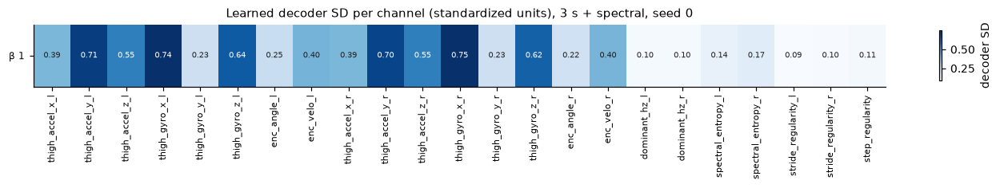

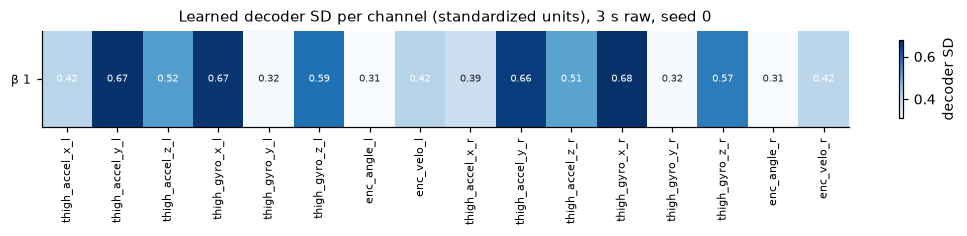

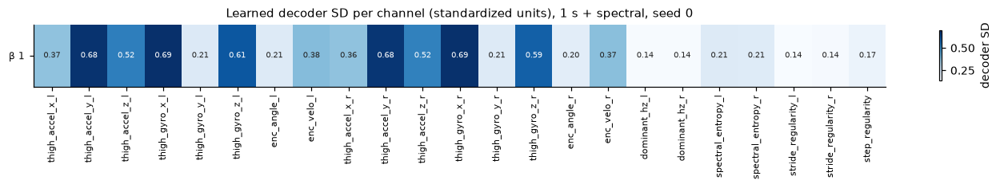

In [6]:
if HAVE_RUNS:
    for inputs, spec in meta['inputs'].items():
        learned = found[(found['decoder_variance'] == 'learned') & (found['seed'] == SHOWN_SEED) & (found['inputs'] == inputs)]
        if learned.empty:
            continue
        channel_names = meta['channels'] + list(spec['features'])
        sigma = pd.DataFrame({f'β {r.beta:g}': runs[r.run]['summary']['decoder_sigma'] for r in learned.itertuples()}, index = channel_names).T
        vr.plot_heatmap(sigma, f'Learned decoder SD per channel (standardized units), {vr.INPUT_SHORT[inputs]}, seed {SHOWN_SEED}', 'decoder SD',
                        '{:.2f}', save = FIG_DIR / f'{NB}_{TAG}_decoder_sigma_{inputs}.png')


## 5. Posterior width by task

Median over each task's validation windows of the mean posterior variance across the run's active dimensions (seed 0).
With the variance fixed, the Science Robotics study found this flat across tasks; this shows whether it still is.
Descriptive only: how well it separates unfamiliar movement is a score, and is notebook 05's.

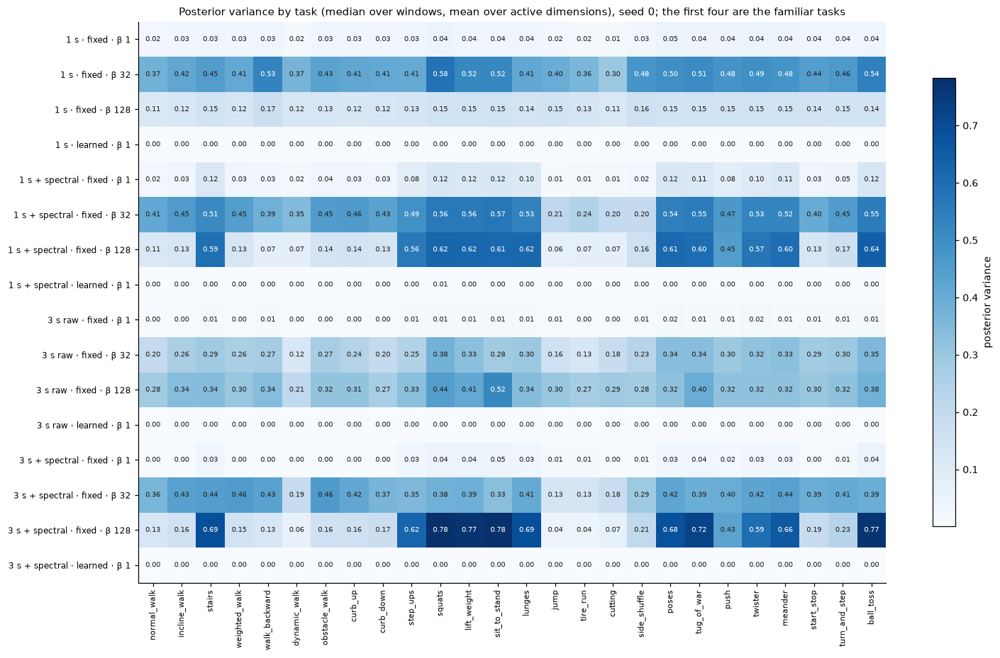

In [7]:
if HAVE_RUNS:
    tasks = list(nt.ID_SAFE_TASKS) + [t for ts in nt.TASK_FAMILIES.values() for t in ts if t not in nt.ID_SAFE_TASKS]
    widths = {}
    for r in shown.itertuples():
        run = runs[r.run]
        familiar = (run['labels']['controller_class'].astype(str) == 'ID-safe').to_numpy()
        widths[vr.get_cell_label(r.inputs, r.decoder_variance, r.beta)] = vr.get_width_by_task(run['labels'], run['logvar'],
                                                                            vr.get_active(run['logvar'], familiar))
    width = pd.DataFrame(widths).T.reindex(columns = tasks)
    vr.plot_heatmap(width, f'Posterior variance by task (median over windows, mean over active dimensions), seed {SHOWN_SEED}; '
                    'the first four are the familiar tasks', 'posterior variance', '{:.2f}')

## 6. Latent maps

Posterior means of up to 250 validation windows per task (the same windows for every run), on the run's active
dimensions, in the three views of notebook 01 (the highest-variance dimensions, PCA, UMAP), coloured by task family and
by controller class. One row per β for each input and decoder variance, seed 0. The windows are
those every run exported, so 1 s and 3 s models are drawn on the same windows.

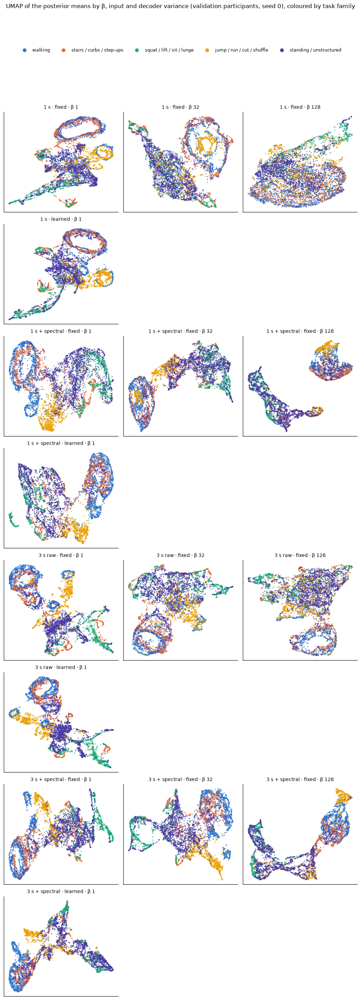

6,500 validation windows, 26 tasks, participants ['BT09', 'BT12', 'BT13', 'BT21']


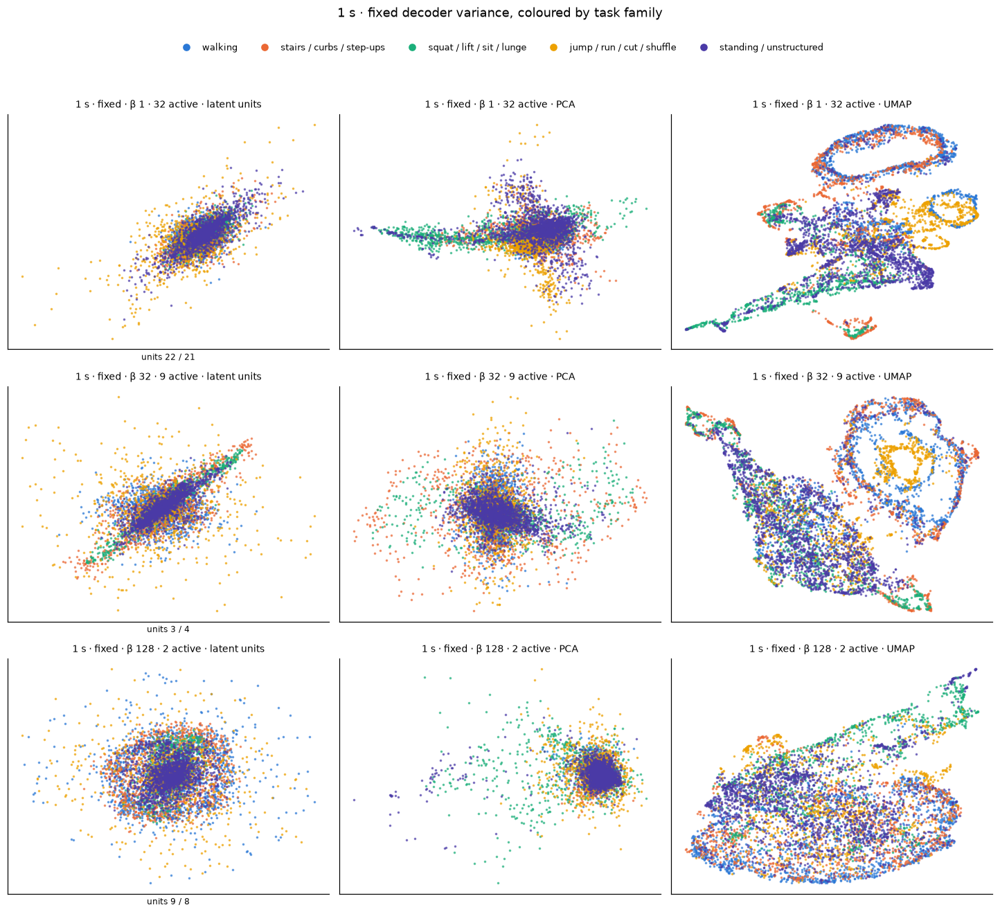

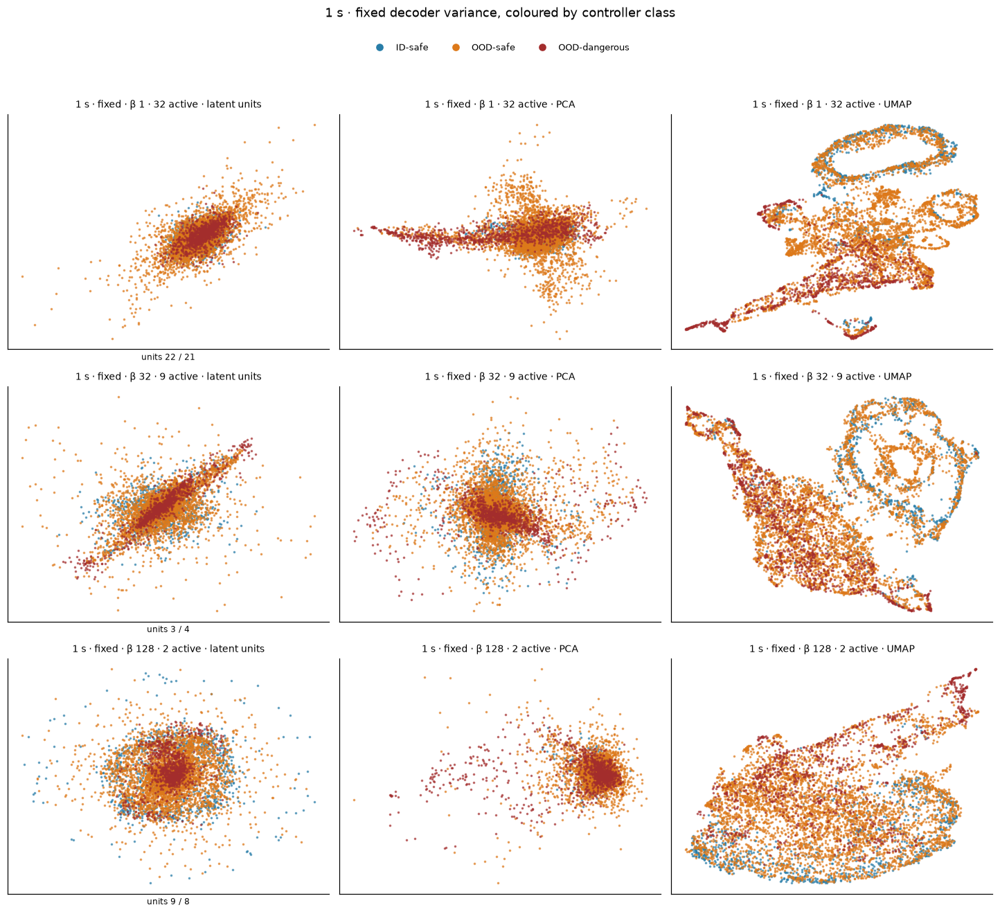

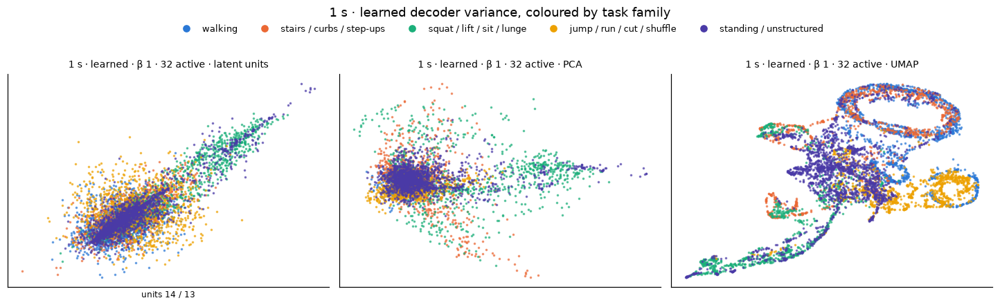

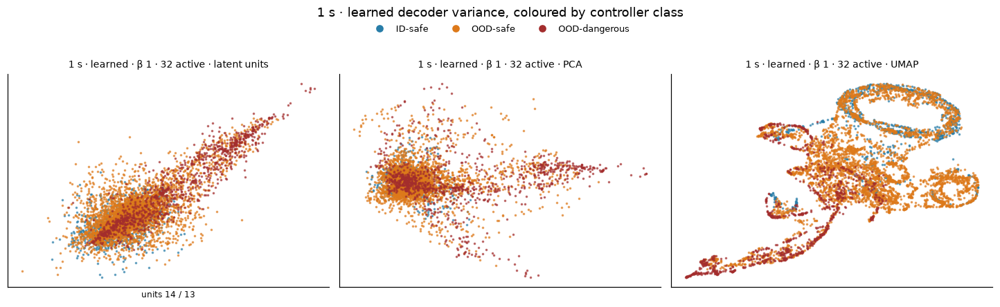

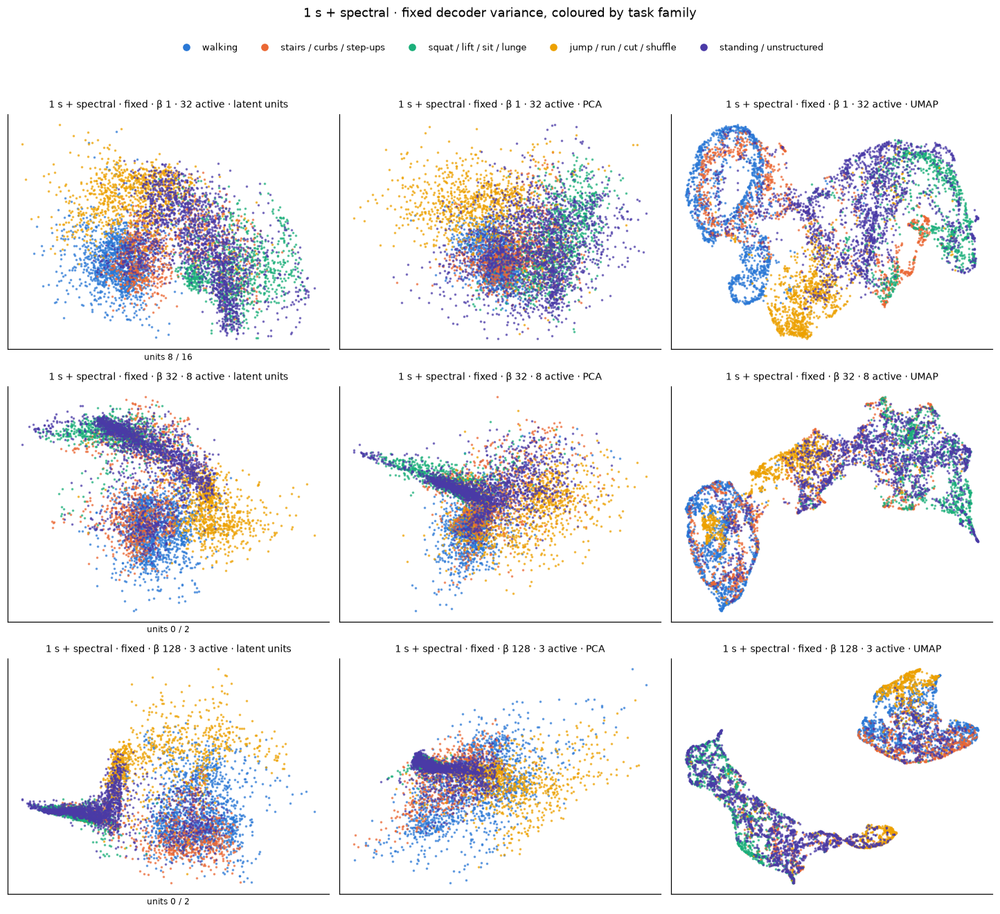

...

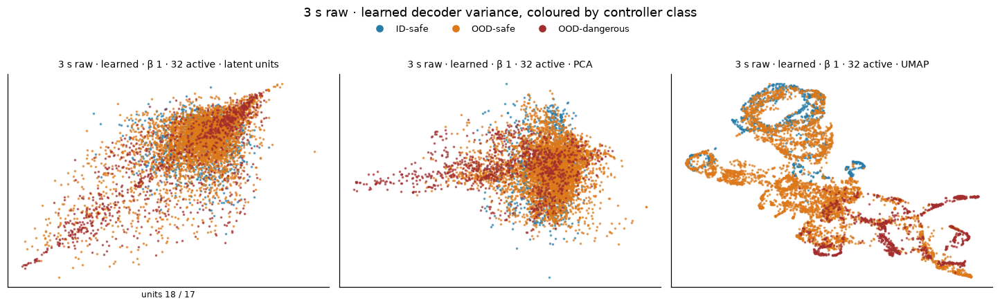

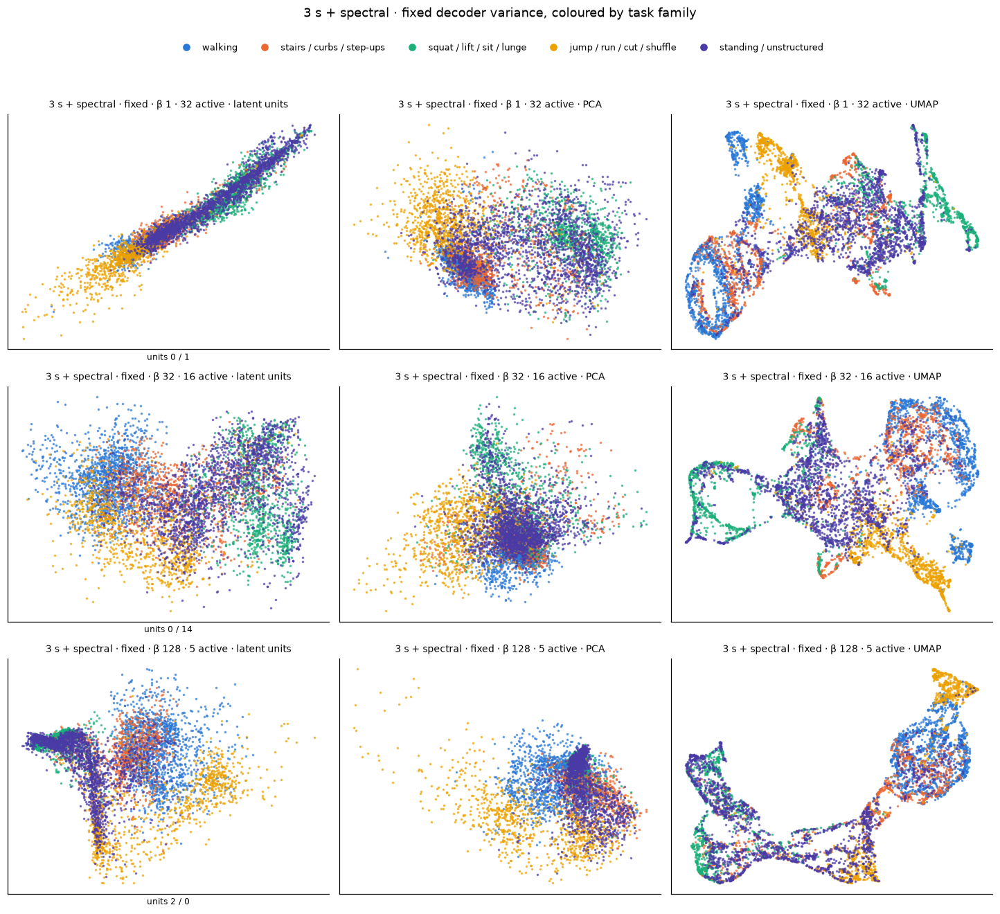

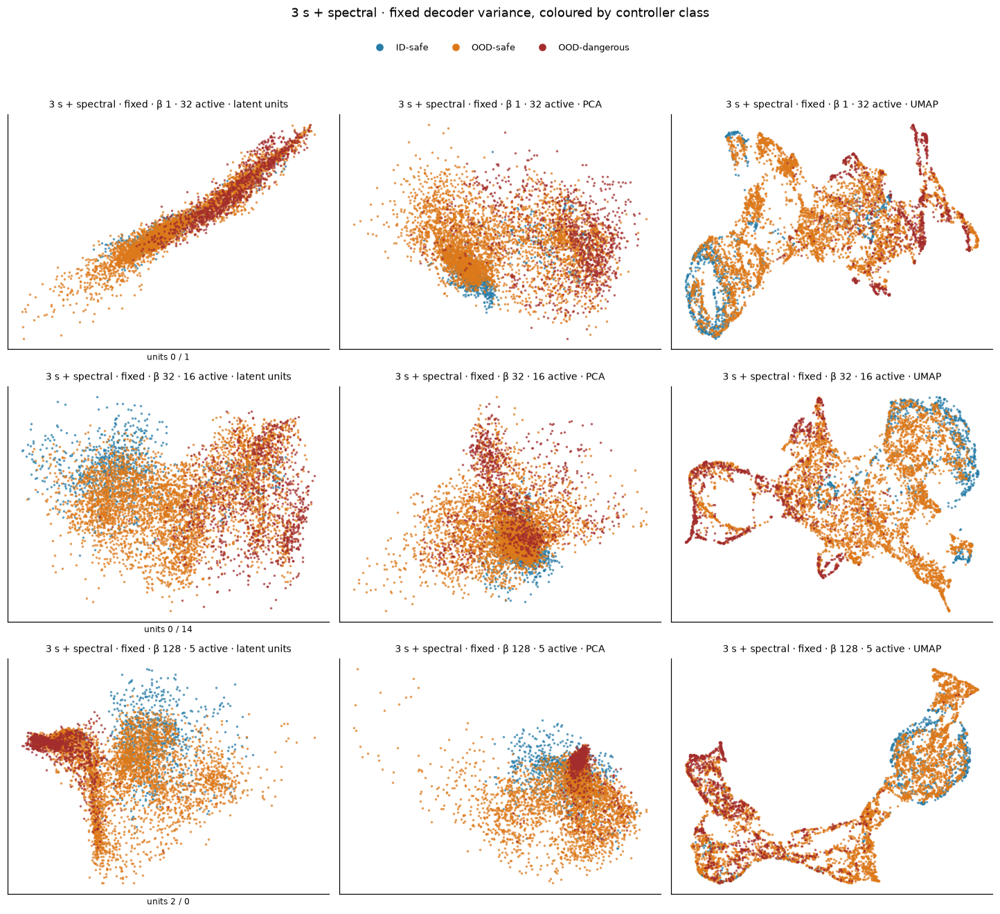

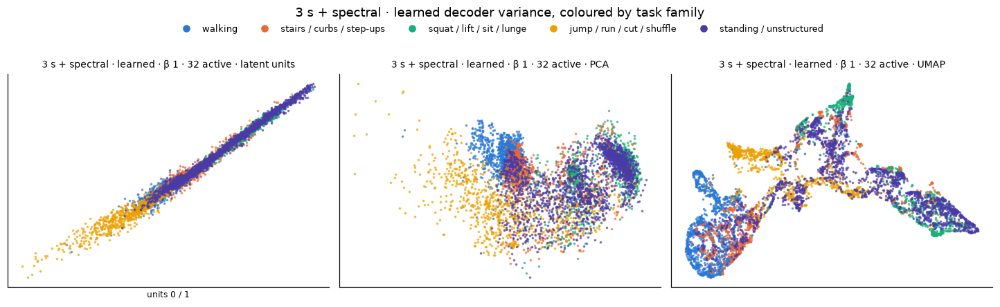

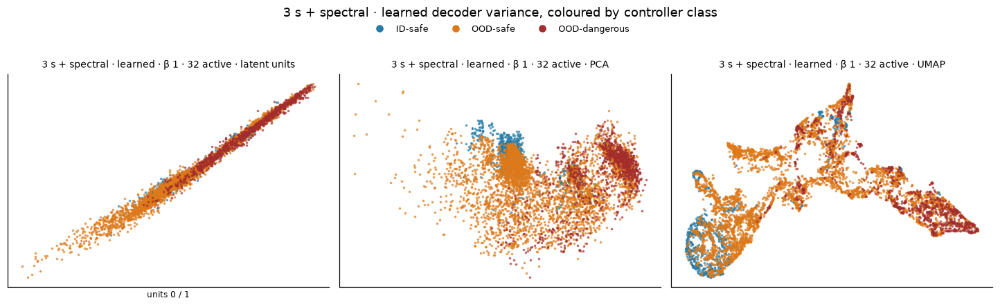

In [8]:
if HAVE_RUNS:
    base = shown.sort_values('inputs', ascending = False).iloc[0]                 # a 3 s run if any: its windows exist in every run
    first = runs[base.run]['labels']
    pick = lv.get_balanced_sample(first, 250, np.random.default_rng(0))
    labels = first.iloc[pick].reset_index(drop = True)
    views, actives = {}, {}
    for r in shown.itertuples():
        run = runs[r.run]
        z = lv.get_aligned_z({'labels': run['labels'], 'z': run['z']}, labels)                  # (N, 32), same windows
        familiar = (run['labels']['controller_class'].astype(str) == 'ID-safe').to_numpy()
        active = vr.get_active(run['logvar'], familiar)
        key = vr.get_cell_label(r.inputs, r.decoder_variance, r.beta)
        views[key], actives[key] = lv.get_views(z[:, active] if active.sum() >= 3 else z, VIEW_CACHE), int(active.sum())
    keyed = {(' · '.join(k.split(' · ')[:2]), float(k.split(' · ')[2].removeprefix('β '))): v for k, v in views.items()}
    vr.plot_umap_by_beta(keyed, labels, 'family', lv.FAMILY_C, lv.BACKGROUND, 'UMAP of the posterior means by β, input and decoder variance '
                         f'(validation participants, seed {SHOWN_SEED}), coloured by task family', FIG_DIR / f'{NB}_{TAG}_umap_by_beta.png')
    print(f'{len(labels):,} validation windows, {labels.task.nunique()} tasks, participants {sorted(labels.subject.astype(str).unique())}')
    for group in dict.fromkeys(k[0] for k in keyed):
        part = {f'{k} · {actives[k]} active': v for k, v in views.items() if k.startswith(group + ' ·')}
        lv.plot_lens_grid(part, labels, 'family', lv.FAMILY_C, f'{group} decoder variance, coloured by task family')
        lv.plot_lens_grid(part, labels, 'controller_class', lv.CLASS_C, f'{group} decoder variance, coloured by controller class')


## 7. Interactive 3-D: the best fixed- and learned-variance TCN-VAE

The two cells drawn are chosen in notebook 05 (section 7.2's rule): for each decoder variance, the cell (β and input)
whose best native score has the highest validation AUROC for unfamiliar against familiar windows. Seed 0, the windows of
section 6 (up to 80 per task here), in 3-D; the dropdown switches view and lens. Besides task, family, controller class and
direction, a **KL quartile** lens colours each window by its KL in that run (light = lowest), because at high β the KL
is that model's novelty signal. Standalone copies are saved in `interactive/`.

In [9]:
import re

RESULTS = Path.cwd() / 'results' / '05_native_scores.csv'                    # written by notebook 05, section 7.2
INTERACTIVE = Path.cwd() / 'interactive'
CONFIG_3D = {'scrollZoom': True, 'displaylogo': False}
KL_C = {'1 lowest': '#c6dbef', '2': '#6baed6', '3': '#2171b5', '4 highest': '#08306b'}   # sequential: one hue, light to dark
if HAVE_RUNS and RESULTS.exists():
    native = pd.read_csv(RESULTS)
    native = native[native['family'] == 'vae']
    val_best = native.groupby(['model', 'score'])['val AUROC, unfamiliar vs familiar'].mean().groupby('model').max()
    found['model'] = [ns.get_model_label(r.config, r.stem) for r in found.itertuples()]
    STYLES = lv.get_task_styles(nt.TASK_FAMILIES)
    lenses = {'task': ('task', {t: STYLES[t]['family'] for ts in nt.TASK_FAMILIES.values() for t in ts}),
              'family': ('family', lv.FAMILY_C), 'controller class': ('controller_class', lv.CLASS_C),
              'direction': ('direction', lv.DIRECTION_C), 'KL quartile': ('kl_quartile', KL_C)}
    rng3 = np.random.default_rng(1)
    show = np.sort(np.concatenate([rng3.choice(np.flatnonzero(labels['task'].astype(str).to_numpy() == t),
                                               min(80, int((labels['task'] == t).sum())), replace = False)
                                    for t in labels['task'].astype(str).unique()]))
    for variance in ('fixed', 'learned'):
        candidates = val_best[[m for m in val_best.index if f'{variance} variance' in m and m.startswith(MODEL_PREFIX)]]
        if candidates.empty:
            print(f'no scored {variance}-variance runs of this architecture in {RESULTS.name} yet: run notebook 05 first')
            continue
        model = candidates.idxmax()
        r = found[(found['model'] == model) & (found['seed'] == SHOWN_SEED)].iloc[0]
        run = runs[r.run]
        idx = run['labels'][['rec', 'end']].reset_index().merge(labels[['rec', 'end']], on = ['rec', 'end'], how = 'right')['index'].to_numpy()
        lab3 = labels.copy()
        lab3['kl_quartile'] = pd.qcut(run['kl'][idx], 4, labels = list(KL_C)).astype(str)
        familiar = (run['labels']['controller_class'].astype(str) == 'ID-safe').to_numpy()
        active = vr.get_active(run['logvar'], familiar)
        z = run['z'][idx]
        v3 = lv.get_views(z[:, active] if active.sum() >= 3 else z, VIEW_CACHE)
        name = f'{model} (validation AUROC {candidates.max():.3f})'
        fig = lv.build_3d({name: {k: v[show] for k, v in v3.items() if k != 'units'}}, lab3.iloc[show].reset_index(drop = True),
                          lenses, {t: s['symbol'] for t, s in STYLES.items()}, name)
        INTERACTIVE.mkdir(exist_ok = True)
        path = INTERACTIVE / f'{TAG}_best_{variance}_3d.html'
        fig.write_html(path, include_plotlyjs = 'cdn', config = CONFIG_3D)
        fig.show(config = CONFIG_3D)
        print(f'best {variance}-variance cell: {model}; standalone copy {path.relative_to(REPO)}')
elif HAVE_RUNS:
    print('Run notebook 05 first: it writes results/05_native_scores.csv, which picks the cells shown here.')

best fixed-variance cell: TCN-VAE · β 1 · fixed variance · 3 s raw; standalone copy notebooks/nature/model_exploration/onboard/interactive/tcn_vae_best_fixed_3d.html


best learned-variance cell: TCN-VAE · β 1 · learned variance · 3 s raw; standalone copy notebooks/nature/model_exploration/onboard/interactive/tcn_vae_best_learned_3d.html


## 8. What this shows

The latent spaces only; detection is notebook 05's (on 3 s raw this model reaches test AUROC 0.950 for unfamiliar and
0.995 for OOD-dangerous windows, the highest dangerous-task AUROC of any model) and notebook 07's (the training-class
ablation).

- **At β 1 it uses its whole code on every input** (32 active dimensions, fixed and learned variance), with a KL close
  to the Transformer VAE's (62 nats per window on 1 s, 91 on 3 s raw) and a reconstruction error between the conv VAE's
  and the Transformer's (0.250 on 1 s, 0.315 on 3 s raw). It reaches its best epoch early (4 to 18 epochs with fixed
  variance), and each run took 2 to 9 minutes on an A100 once compiled.
- **β prunes it without collapse.** Unlike the LSTM-VAE (notebook 03), whose posterior collapses at β 128 on raw input,
  the TCN-VAE keeps a small code there: 2 dimensions on 1 s raw, 3 on 1 s + spectral, 8 on 3 s raw and 5 on 3 s +
  spectral (β 32: 8 to 15). The dilated convolutions give the decoder a direct use for every latent step.
- **Its posterior width tracks posture, not familiarity.** At β 128 with the spectral input the median posterior variance
  is 0.59 to 0.78 on squats, lifting, sit-to-stand, lunges, standing poses, tug of war and the ball toss, 0.13 to 0.17 on
  walking, curbs and the other cyclic tasks, and 0.04 to 0.07 on jumping, running and cutting (5). Stairs (familiar)
  is wide too (0.69), so width alone is not a novelty score; in notebook 05 its posterior variance reaches 0.85 on 3 s
  raw, below LOF (0.950).
- **Its latent maps look like the Transformer VAE's** (6): gait rings for walking and stairs, a loop for jumping and
  running and the standing tasks in the middle on 1 s; on 3 s raw the families separate further. Linear CKA with the
  Transformer VAE's 3 s raw latent is 0.76, with the plain AE's 0.66 and the LSTM-VAE's 0.52 (notebook 05, section 9.4).
- **The 3-D pages** (7): β 1 on 3 s raw for both decoder variances, chosen on validation in notebook 05.